In [12]:

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [13]:
# load cleaned data
df = pd.read_csv('data_after_cleaning.csv')

In [14]:

# removing whitespaces from crop and season column
df['crop']=df['crop'].str.replace(' ','')
df['season']=df['season'].str.replace(' ','')

In [15]:
# for traing forecaste model the years are should be in sequence
df = df.sort_values(by='crop_year')

In [92]:

df

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude,crop_yield
29,2001,wholeyear,banana,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,0.256219
30,2001,wholeyear,coconut,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,8.185731
31,2001,wholeyear,coriander,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,0.211902
4,2001,kharif,drychillies,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,1.062281
5,2001,kharif,groundnut,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,0.364643
...,...,...,...,...,...,...,...,...,...,...,...
249491,2020,rabi,wheat,9.114160,12.551224,2.734038,60.397664,3.186096,30.729860,78.443420,0.983564
249460,2020,wholeyear,turmeric,0.693147,12.463553,6.557644,56.127426,3.479982,30.608720,79.065170,1.098612
249485,2020,rabi,wheat,9.965476,7.998832,2.927197,71.856507,5.530812,29.390529,79.460869,1.573525
249431,2020,kharif,soyabean,3.610918,19.961075,13.932401,85.659140,3.244839,30.008790,79.928018,0.693147


In [16]:
# spliting data into train and test 
train_df = df[df['crop_year'] <= 2018]
test_df = df[df['crop_year'] > 2018]

In [17]:
x_train = train_df.drop(columns=['crop_yield'])
y_train = train_df['crop_yield']

x_test = test_df.drop(columns=['crop_yield'])
y_test = test_df['crop_yield']

In [18]:
x_train

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude
29,2001,wholeyear,banana,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
30,2001,wholeyear,coconut,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
31,2001,wholeyear,coriander,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
4,2001,kharif,drychillies,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
5,2001,kharif,groundnut,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
...,...,...,...,...,...,...,...,...,...,...
196288,2018,rabi,arhar/tur,1.098612,25.017684,1.910772,62.669355,7.916935,13.202648,79.003225
196289,2018,kharif,arhar/tur,7.249215,28.528459,10.305771,79.246595,12.974588,16.995664,81.715438
196290,2018,rabi,arhar/tur,3.688879,27.781336,0.096774,61.963134,8.025518,16.995664,81.715438
196291,2018,kharif,arhar/tur,9.849506,29.967455,5.471541,67.559857,12.334659,16.291519,80.454159


In [19]:

x_test

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude
233190,2019,rabi,onion,6.526495,21.215668,0.823214,61.295507,9.224021,26.276809,86.795961
249168,2019,rabi,wheat,7.289611,23.875864,1.349309,65.630184,7.938191,22.420000,87.320000
249169,2019,rabi,wheat,10.872560,22.873675,1.235138,61.213134,7.837558,24.174599,88.272133
249170,2019,rabi,wheat,8.730529,22.787903,1.685599,66.779378,7.476382,23.484737,88.556707
249171,2019,rabi,wheat,7.513709,22.922062,1.677477,65.107143,7.409447,23.388409,87.960676
...,...,...,...,...,...,...,...,...,...,...
249491,2020,rabi,wheat,9.114160,12.551224,2.734038,60.397664,3.186096,30.729860,78.443420
249460,2020,wholeyear,turmeric,0.693147,12.463553,6.557644,56.127426,3.479982,30.608720,79.065170
249485,2020,rabi,wheat,9.965476,7.998832,2.927197,71.856507,5.530812,29.390529,79.460869
249431,2020,kharif,soyabean,3.610918,19.961075,13.932401,85.659140,3.244839,30.008790,79.928018


In [20]:
# some models require scaling before training so make a copy of train and test data
x_train_encoding  = x_train.copy()
x_test_encoding = x_test.copy()


Encoding of categorical data

In [21]:
crop_encoder = LabelEncoder()
x_train_encoding['crop_encoded'] = crop_encoder.fit_transform(x_train_encoding['crop'])

In [22]:

x_train_encoding

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude,crop_encoded
29,2001,wholeyear,banana,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,5
30,2001,wholeyear,coconut,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,22
31,2001,wholeyear,coriander,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,24
4,2001,kharif,drychillies,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,28
5,2001,kharif,groundnut,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,34
...,...,...,...,...,...,...,...,...,...,...,...
196288,2018,rabi,arhar/tur,1.098612,25.017684,1.910772,62.669355,7.916935,13.202648,79.003225,2
196289,2018,kharif,arhar/tur,7.249215,28.528459,10.305771,79.246595,12.974588,16.995664,81.715438,2
196290,2018,rabi,arhar/tur,3.688879,27.781336,0.096774,61.963134,8.025518,16.995664,81.715438,2
196291,2018,kharif,arhar/tur,9.849506,29.967455,5.471541,67.559857,12.334659,16.291519,80.454159,2


In [23]:
x_train

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude
29,2001,wholeyear,banana,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
30,2001,wholeyear,coconut,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
31,2001,wholeyear,coriander,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
4,2001,kharif,drychillies,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
5,2001,kharif,groundnut,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
...,...,...,...,...,...,...,...,...,...,...
196288,2018,rabi,arhar/tur,1.098612,25.017684,1.910772,62.669355,7.916935,13.202648,79.003225
196289,2018,kharif,arhar/tur,7.249215,28.528459,10.305771,79.246595,12.974588,16.995664,81.715438
196290,2018,rabi,arhar/tur,3.688879,27.781336,0.096774,61.963134,8.025518,16.995664,81.715438
196291,2018,kharif,arhar/tur,9.849506,29.967455,5.471541,67.559857,12.334659,16.291519,80.454159


In [24]:
x_test_encoding['crop_encoded'] = crop_encoder.transform(x_test_encoding['crop'])

In [25]:
x_test_encoding['crop_encoded']

233190    52
249168    91
249169    91
249170    91
249171    91
          ..
249491    91
249460    87
249485    91
249431    79
249468    89
Name: crop_encoded, Length: 18552, dtype: int64

In [26]:
season_encoder = LabelEncoder()
x_train_encoding['season_encoded'] = season_encoder.fit_transform(x_train_encoding['season'])

In [27]:

x_train_encoding['season_encoded']

29        4
30        4
31        4
4         1
5         1
         ..
196288    2
196289    1
196290    2
196291    1
213549    0
Name: season_encoded, Length: 230940, dtype: int64

In [28]:

x_test_encoding['season_encoded'] = season_encoder.transform(x_test_encoding['season'])

In [29]:
x_test_encoding['season_encoded']

233190    2
249168    2
249169    2
249170    2
249171    2
         ..
249491    2
249460    4
249485    2
249431    1
249468    3
Name: season_encoded, Length: 18552, dtype: int64

In [30]:

# now drop categorical data and keep thier encoding columns
x_train_for_scaling = x_train_encoding.drop(['crop','season'],axis=1)

In [31]:

x_train_for_scaling

,crop_year,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude,crop_encoded,season_encoded
29,2001,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,5,4
30,2001,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,22,4
31,2001,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674,24,4
4,2001,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,28,1
5,2001,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674,34,1
...,...,...,...,...,...,...,...,...,...,...
196288,2018,1.098612,25.017684,1.910772,62.669355,7.916935,13.202648,79.003225,2,2
196289,2018,7.249215,28.528459,10.305771,79.246595,12.974588,16.995664,81.715438,2,1
196290,2018,3.688879,27.781336,0.096774,61.963134,8.025518,16.995664,81.715438,2,2
196291,2018,9.849506,29.967455,5.471541,67.559857,12.334659,16.291519,80.454159,2,1


In [32]:
x_test_for_scaling = x_test_encoding.drop(['crop','season'],axis=1)

In [33]:
x_test_for_scaling

,crop_year,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude,crop_encoded,season_encoded
233190,2019,6.526495,21.215668,0.823214,61.295507,9.224021,26.276809,86.795961,52,2
249168,2019,7.289611,23.875864,1.349309,65.630184,7.938191,22.420000,87.320000,91,2
249169,2019,10.872560,22.873675,1.235138,61.213134,7.837558,24.174599,88.272133,91,2
249170,2019,8.730529,22.787903,1.685599,66.779378,7.476382,23.484737,88.556707,91,2
249171,2019,7.513709,22.922062,1.677477,65.107143,7.409447,23.388409,87.960676,91,2
...,...,...,...,...,...,...,...,...,...,...
249491,2020,9.114160,12.551224,2.734038,60.397664,3.186096,30.729860,78.443420,91,2
249460,2020,0.693147,12.463553,6.557644,56.127426,3.479982,30.608720,79.065170,87,4
249485,2020,9.965476,7.998832,2.927197,71.856507,5.530812,29.390529,79.460869,91,2
249431,2020,3.610918,19.961075,13.932401,85.659140,3.244839,30.008790,79.928018,79,1


In [34]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_for_scaling)
x_train_scaled.shape

(230940, 10)

In [35]:

x_test_scaled = scaler.transform(x_test_for_scaling)

In [36]:

x_test

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude
233190,2019,rabi,onion,6.526495,21.215668,0.823214,61.295507,9.224021,26.276809,86.795961
249168,2019,rabi,wheat,7.289611,23.875864,1.349309,65.630184,7.938191,22.420000,87.320000
249169,2019,rabi,wheat,10.872560,22.873675,1.235138,61.213134,7.837558,24.174599,88.272133
249170,2019,rabi,wheat,8.730529,22.787903,1.685599,66.779378,7.476382,23.484737,88.556707
249171,2019,rabi,wheat,7.513709,22.922062,1.677477,65.107143,7.409447,23.388409,87.960676
...,...,...,...,...,...,...,...,...,...,...
249491,2020,rabi,wheat,9.114160,12.551224,2.734038,60.397664,3.186096,30.729860,78.443420
249460,2020,wholeyear,turmeric,0.693147,12.463553,6.557644,56.127426,3.479982,30.608720,79.065170
249485,2020,rabi,wheat,9.965476,7.998832,2.927197,71.856507,5.530812,29.390529,79.460869
249431,2020,kharif,soyabean,3.610918,19.961075,13.932401,85.659140,3.244839,30.008790,79.928018


1. Catboost model training

In [37]:

x_val = x_test[:1000]
y_val = y_test[:1000]
x_test_final = x_test[1000:]
y_test_final = y_test[1000:]

In [38]:
from catboost import CatBoostRegressor, Pool

In [40]:
train_pool = Pool(data=x_train, label=y_train, cat_features=categorical_features)
test_val_pool = Pool(data=x_val, label=y_val, cat_features=categorical_features)
test_pool = Pool(data=x_test_final, label=y_test_final, cat_features=categorical_features)

In [117]:

x_train.columns , x_val.columns , x_test_final.columns

(Index(['crop_year', 'season', 'crop', 'area', 'temperature_2m_mean',
        'precipitation_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_mean',
        'latitude', 'longitude'],
       dtype='str'),
 Index(['crop_year', 'season', 'crop', 'area', 'temperature_2m_mean',
        'precipitation_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_mean',
        'latitude', 'longitude'],
       dtype='str'),
 Index(['crop_year', 'season', 'crop', 'area', 'temperature_2m_mean',
        'precipitation_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_mean',
        'latitude', 'longitude'],
       dtype='str'))

In [39]:
categorical_features = ['season','crop']

In [119]:
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [120]:

from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [121]:
model_pool = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    eval_metric='RMSE',
    verbose=100,
    early_stopping_rounds=50
)

In [122]:
model_pool.fit(train_pool, eval_set=test_val_pool, use_best_model=True, early_stopping_rounds=50)

0:	learn: 1.1251527	test: 1.3026522	best: 1.3026522 (0)	total: 72.1ms	remaining: 1m 12s
100:	learn: 0.5100909	test: 0.6125845	best: 0.6125845 (100)	total: 8.39s	remaining: 1m 14s
200:	learn: 0.4592685	test: 0.5645918	best: 0.5645918 (200)	total: 16.9s	remaining: 1m 7s
300:	learn: 0.4358850	test: 0.5490518	best: 0.5489743 (298)	total: 25.5s	remaining: 59.1s
400:	learn: 0.4190007	test: 0.5261938	best: 0.5261249 (398)	total: 34.8s	remaining: 52s
500:	learn: 0.4073100	test: 0.5159886	best: 0.5157163 (496)	total: 45.6s	remaining: 45.4s
600:	learn: 0.3951548	test: 0.5076728	best: 0.5075374 (596)	total: 54.9s	remaining: 36.5s
700:	learn: 0.3860278	test: 0.5050675	best: 0.5050673 (699)	total: 1m 4s	remaining: 27.7s
800:	learn: 0.3773663	test: 0.5009470	best: 0.5009470 (800)	total: 1m 14s	remaining: 18.4s
900:	learn: 0.3705801	test: 0.4967722	best: 0.4967722 (900)	total: 1m 23s	remaining: 9.15s
999:	learn: 0.3645644	test: 0.4948293	best: 0.4937753 (966)	total: 1m 32s	remaining: 0us

bestTest = 

CatBoostRegressor(depth=6, early_stopping_rounds=50, eval_metric='RMSE', iterations=1000, learning_rate=0.1, loss_function='RMSE', verbose=100)

In [123]:
model_pool.best_score_

{'learn': {'RMSE': 0.36456440524628625},
 'validation': {'RMSE': 0.49377530672299746}}

In [124]:
y_test_pool_predict = model_pool.predict(test_pool) 
y_train_pool_predict = model_pool.predict(train_pool)
test_pool_score = mean_squared_error(y_test_final,y_test_pool_predict)
train_pool_score = mean_squared_error(y_train,y_train_pool_predict)
test_pool_score,train_pool_score

(0.20344654868187162, 0.1313577179526078)

In [125]:

test_r2 = r2_score(y_test_final,y_test_pool_predict)
train_r2 = r2_score(y_train,y_train_pool_predict)
test_r2,train_r2

(0.8540069912677845, 0.9078039935472507)

2. LightGBM model training

In [126]:

import lightgbm as lgb
from sklearn.metrics import r2_score, root_mean_squared_error

In [127]:
#Convert categorical columns to 'category' dtype
for col in ['crop', 'season']:
    x_train[col] = x_train[col].astype('category')
    x_test[col] = x_test[col].astype('category')

In [128]:

model_lgbm = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=100,
    learning_rate=0.1,
    
)

In [129]:

x_train

,crop_year,season,crop,area,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_mean,latitude,longitude
29,2001,wholeyear,banana,7.367077,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
30,2001,wholeyear,coconut,6.747587,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
31,2001,wholeyear,coriander,8.464214,26.936137,1.614875,58.895437,13.118321,14.724220,77.430674
4,2001,kharif,drychillies,8.233769,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
5,2001,kharif,groundnut,13.539363,27.047742,1.125806,65.310753,21.165090,14.724220,77.430674
...,...,...,...,...,...,...,...,...,...,...
196288,2018,rabi,arhar/tur,1.098612,25.017684,1.910772,62.669355,7.916935,13.202648,79.003225
196289,2018,kharif,arhar/tur,7.249215,28.528459,10.305771,79.246595,12.974588,16.995664,81.715438
196290,2018,rabi,arhar/tur,3.688879,27.781336,0.096774,61.963134,8.025518,16.995664,81.715438
196291,2018,kharif,arhar/tur,9.849506,29.967455,5.471541,67.559857,12.334659,16.291519,80.454159


In [130]:

model_lgbm.fit(x_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001795 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1901
[LightGBM] [Info] Number of data points in the train set: 230940, number of used features: 10
[LightGBM] [Info] Start training from score 1.186788


,objective,'regression'
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [131]:
y_test_lgbm_predict = model_lgbm.predict(x_test)
y_train_lgbm_predict = model_lgbm.predict(x_train)

In [132]:
r2_test_lgbm = r2_score(y_test,y_test_lgbm_predict)
r2_train_lgbm = r2_score(y_train,y_train_lgbm_predict)
r2_test_lgbm, r2_train_lgbm

(0.8551377053253354, 0.9013742889393332)

In [133]:
rmse_test_lgbm = root_mean_squared_error(y_test,y_test_lgbm_predict)
rmse_train_lgbm = root_mean_squared_error(y_train,y_train_lgbm_predict)
rmse_test_lgbm, rmse_train_lgbm

(0.45330057447382704, 0.37485802813351227)

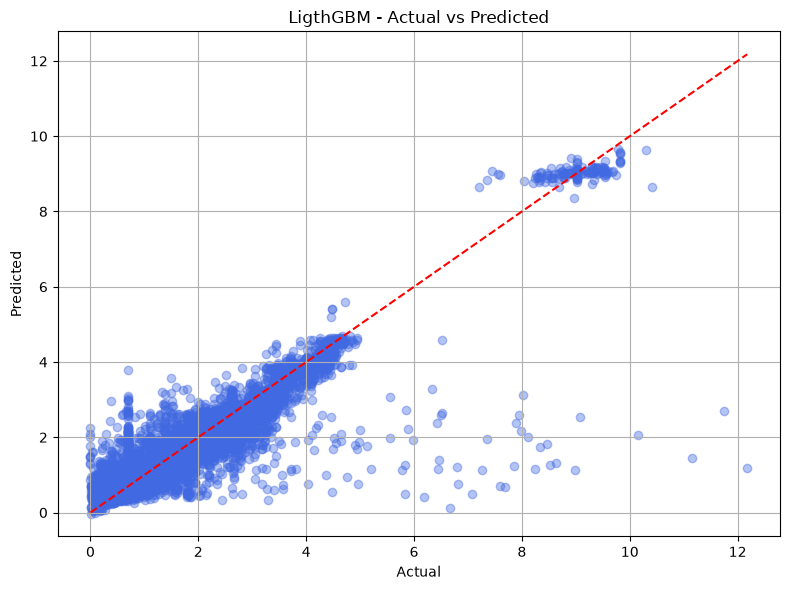

In [134]:

#Plot predictions vs actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_lgbm_predict, alpha=0.4, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('LigthGBM - Actual vs Predicted')
plt.grid(True)
plt.tight_layout()
plt.show()

3. XGBoostRegression model traning

In [135]:

from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

In [136]:
reg = XGBRegressor(objective='reg:squarederror', enable_categorical=True, tree_method='hist')

In [137]:

# Grid parameters
param_grid = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [50, 100],
    'subsample': [0.8, 1.0]
}

In [138]:
model_xgb = GridSearchCV(estimator=reg, param_grid=param_grid, 
                           cv=3, scoring='neg_mean_squared_error', verbose=1, n_jobs=-1)

In [139]:

x_train_scaled

array([[-1.82080311,  0.2165142 ,  0.38424885, ..., -0.59904739,
        -1.83447609,  1.49961352],
       [-1.82080311, -0.01861308,  0.38424885, ..., -0.59904739,
        -1.17458158,  1.49961352],
       [-1.82080311,  0.63293199,  0.38424885, ..., -0.59904739,
        -1.09694693,  1.49961352],
       ...,
       [ 1.42760475, -1.17954357,  0.58384687, ...,  0.11648183,
        -1.95092806, -0.09431833],
       [ 1.42760475,  1.15871883,  1.10010985, ..., -0.094144  ,
        -1.95092806, -0.89128426],
       [ 1.42760475,  0.28096931,  0.34404975, ...,  1.15961693,
         0.76628464, -1.68825019]], shape=(230940, 10))

In [140]:

model_xgb.fit(x_train_scaled, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [4, 6, ...], 'n_estimators': [50, 100], 'subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto

In [142]:

y_test_xgb_predict = model_xgb.predict(x_test_scaled)
y_train_xgb_predict = model_xgb.predict(x_train_scaled)

In [143]:
r2_test_xgb = r2_score(y_test,y_test_xgb_predict)
r2_train_xgb = r2_score(y_train,y_train_xgb_predict)
r2_test_xgb, r2_train_xgb

(0.8546695311917796, 0.9296263705440456)

4.Neural network (ANN)

In [144]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout,Input,LSTM
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [145]:
x_val_NN = x_test_for_scaling[:1000]
y_val_NN = y_test[:1000]
x_test_final_NN = x_test_for_scaling[1000:]
y_test_final_NN= y_test[1000:]

In [146]:
X_val = scaler.transform(x_val_NN)
X_test = scaler.transform(x_test_final_NN)

In [147]:
len(X_val),len(y_val_NN)

(1000, 1000)

In [148]:

x_train_scaled.shape

(230940, 10)

In [149]:
len(x_train_scaled),len(y_train)

(230940, 230940)

In [150]:
model_nn = Sequential([
    Dense(128, input_dim=10, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1)
    
    ])
model_nn.compile(optimizer=Adam(learning_rate=0.01), loss='mse', metrics=['mae','r2_score'])

a:\anoconda3\envs\tensorflow\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [151]:

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [152]:

model_nn.fit(
    x_train_scaled, y_train,
    validation_data=(X_val, y_val_NN),
    epochs=100,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.1577 - mae: 0.6776 - r2_score: 0.1874 - val_loss: 1.3963 - val_mae: 0.6671 - val_r2_score: 0.2447
Epoch 2/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.9555 - mae: 0.6225 - r2_score: 0.3294 - val_loss: 1.3026 - val_mae: 0.6766 - val_r2_score: 0.2954
Epoch 3/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.8734 - mae: 0.6028 - r2_score: 0.3870 - val_loss: 1.1756 - val_mae: 0.6492 - val_r2_score: 0.3641
Epoch 4/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.7895 - mae: 0.5799 - r2_score: 0.4459 - val_loss: 0.9790 - val_mae: 0.5940 - val_r2_score: 0.4705
Epoch 5/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.7482 - mae: 0.5644 - r2_score: 0.4749 - val_loss: 0.8708 - val_mae: 0.6078 - val_r2_score: 0.5290
Epoch 6/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.7132 - mae: 0.5530 - r2_score: 0.4994 - val_loss: 0.8838 - val_mae: 0.5920 - val_r2_score: 0.5219
Epoch 7/100
452/452 ━━━━━━━━━━━━━━

In [153]:

y_test_nn_predict = model_nn.predict(x_test_final_NN)
y_train_nn_predict = model_nn.predict(x_train_scaled)

549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 760us/step
7217/7217 ━━━━━━━━━━━━━━━━━━━━ 5s 701us/step


In [154]:

r2_test_nn = r2_score(y_test_final_NN,y_test_nn_predict)
r2_train_nn = r2_score(y_train,y_train_nn_predict)
r2_test_nn, r2_train_nn

(-12.805334155453215, 0.6929580583667503)

LSTM NN

In [156]:

x_train_scaled_lstm = x_train_scaled.reshape((x_train_scaled.shape[0], 1, x_train_scaled.shape[1]))
X_val_lstm = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

In [157]:
import tensorflow as tf
from tensorflow.keras.models import Model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def build_lstm_model(input_shape):
    inputs = Input(shape=input_shape)
    x = LSTM(128, return_sequences=False)(inputs)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)

    x = Dense(32, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)

    outputs = Dense(1)(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='mse', metrics=['mae'])
    return model
input_shape = (x_train_scaled_lstm.shape[1], x_train_scaled_lstm.shape[2])

model_lstm = build_lstm_model(input_shape)

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1),
    ModelCheckpoint('best_model.h5', monitor='val_loss', save_best_only=True, verbose=1)
]

#  Train the Model
history = model_lstm.fit(
    x_train_scaled_lstm, y_train,
    validation_data=(X_val_lstm, y_val_NN),
    epochs=100,
    batch_size=1024,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.8302 - mae: 0.9128
Epoch 1: val_loss improved from None to 1.93280, saving model to best_model.h5



Epoch 1: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 1.8230 - mae: 0.9109 - val_loss: 1.9328 - val_mae: 0.7275 - learning_rate: 0.0010
Epoch 2/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.2129 - mae: 0.7176
Epoch 2: val_loss improved from 1.93280 to 1.66008, saving model to best_model.h5



Epoch 2: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.2129 - mae: 0.7176 - val_loss: 1.6601 - val_mae: 0.7037 - learning_rate: 0.0010
Epoch 3/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.1290 - mae: 0.6829
Epoch 3: val_loss improved from 1.66008 to 1.35930, saving model to best_model.h5



Epoch 3: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.1284 - mae: 0.6827 - val_loss: 1.3593 - val_mae: 0.6657 - learning_rate: 0.0010
Epoch 4/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0776 - mae: 0.6631
Epoch 4: val_loss improved from 1.35930 to 1.29696, saving model to best_model.h5



Epoch 4: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.0772 - mae: 0.6631 - val_loss: 1.2970 - val_mae: 0.6487 - learning_rate: 0.0010
Epoch 5/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0437 - mae: 0.6496
Epoch 5: val_loss improved from 1.29696 to 1.27318, saving model to best_model.h5



Epoch 5: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.0444 - mae: 0.6496 - val_loss: 1.2732 - val_mae: 0.6639 - learning_rate: 0.0010
Epoch 6/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0184 - mae: 0.6394
Epoch 6: val_loss improved from 1.27318 to 1.23942, saving model to best_model.h5



Epoch 6: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.0176 - mae: 0.6394 - val_loss: 1.2394 - val_mae: 0.6472 - learning_rate: 0.0010
Epoch 7/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9973 - mae: 0.6311
Epoch 7: val_loss improved from 1.23942 to 1.17118, saving model to best_model.h5



Epoch 7: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.9945 - mae: 0.6309 - val_loss: 1.1712 - val_mae: 0.6128 - learning_rate: 0.0010
Epoch 8/100
222/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9649 - mae: 0.6229
Epoch 8: val_loss improved from 1.17118 to 1.11259, saving model to best_model.h5



Epoch 8: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.9647 - mae: 0.6229 - val_loss: 1.1126 - val_mae: 0.6175 - learning_rate: 0.0010
Epoch 9/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9309 - mae: 0.6159
Epoch 9: val_loss did not improve from 1.11259
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.9306 - mae: 0.6158 - val_loss: 1.1377 - val_mae: 0.6176 - learning_rate: 0.0010
Epoch 10/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.8862 - mae: 0.6070
Epoch 10: val_loss improved from 1.11259 to 1.01291, saving model to best_model.h5



Epoch 10: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.8860 - mae: 0.6070 - val_loss: 1.0129 - val_mae: 0.6050 - learning_rate: 0.0010
Epoch 11/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.8398 - mae: 0.5961
Epoch 11: val_loss improved from 1.01291 to 0.97990, saving model to best_model.h5



Epoch 11: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.8391 - mae: 0.5961 - val_loss: 0.9799 - val_mae: 0.6048 - learning_rate: 0.0010
Epoch 12/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.7914 - mae: 0.5835
Epoch 12: val_loss improved from 0.97990 to 0.83530, saving model to best_model.h5



Epoch 12: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.7912 - mae: 0.5835 - val_loss: 0.8353 - val_mae: 0.5742 - learning_rate: 0.0010
Epoch 13/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.7660 - mae: 0.5743
Epoch 13: val_loss improved from 0.83530 to 0.80544, saving model to best_model.h5



Epoch 13: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.7652 - mae: 0.5742 - val_loss: 0.8054 - val_mae: 0.5661 - learning_rate: 0.0010
Epoch 14/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.7443 - mae: 0.5677
Epoch 14: val_loss improved from 0.80544 to 0.79133, saving model to best_model.h5



Epoch 14: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.7435 - mae: 0.5675 - val_loss: 0.7913 - val_mae: 0.5581 - learning_rate: 0.0010
Epoch 15/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7280 - mae: 0.5613
Epoch 15: val_loss did not improve from 0.79133
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.7278 - mae: 0.5613 - val_loss: 0.8097 - val_mae: 0.5658 - learning_rate: 0.0010
Epoch 16/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7101 - mae: 0.5546
Epoch 16: val_loss improved from 0.79133 to 0.79082, saving model to best_model.h5



Epoch 16: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.7097 - mae: 0.5545 - val_loss: 0.7908 - val_mae: 0.5629 - learning_rate: 0.0010
Epoch 17/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7026 - mae: 0.5494
Epoch 17: val_loss improved from 0.79082 to 0.77241, saving model to best_model.h5



Epoch 17: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.7027 - mae: 0.5495 - val_loss: 0.7724 - val_mae: 0.5582 - learning_rate: 0.0010
Epoch 18/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6844 - mae: 0.5454
Epoch 18: val_loss did not improve from 0.77241
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6844 - mae: 0.5454 - val_loss: 0.8945 - val_mae: 0.5859 - learning_rate: 0.0010
Epoch 19/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6743 - mae: 0.5399
Epoch 19: val_loss improved from 0.77241 to 0.75428, saving model to best_model.h5



Epoch 19: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6736 - mae: 0.5397 - val_loss: 0.7543 - val_mae: 0.5485 - learning_rate: 0.0010
Epoch 20/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6658 - mae: 0.5351
Epoch 20: val_loss did not improve from 0.75428
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6658 - mae: 0.5351 - val_loss: 0.7685 - val_mae: 0.5571 - learning_rate: 0.0010
Epoch 21/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6513 - mae: 0.5307
Epoch 21: val_loss did not improve from 0.75428
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6509 - mae: 0.5307 - val_loss: 0.7861 - val_mae: 0.5566 - learning_rate: 0.0010
Epoch 22/100
222/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6410 - mae: 0.5255
Epoch 22: val_loss did not improve from 0.75428
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6416 - mae: 0.5257 - val_loss: 0.7587 - val_mae: 0.5533 - learning_rate: 0.0010
Epoch 23/100
222/226 ━━━━━


Epoch 24: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6236 - mae: 0.5185 - val_loss: 0.7520 - val_mae: 0.5510 - learning_rate: 0.0010
Epoch 25/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6134 - mae: 0.5132
Epoch 25: val_loss improved from 0.75200 to 0.73633, saving model to best_model.h5



Epoch 25: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.6139 - mae: 0.5133 - val_loss: 0.7363 - val_mae: 0.5415 - learning_rate: 0.0010
Epoch 26/100
222/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6093 - mae: 0.5112
Epoch 26: val_loss did not improve from 0.73633
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.6078 - mae: 0.5110 - val_loss: 0.7519 - val_mae: 0.5420 - learning_rate: 0.0010
Epoch 27/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6023 - mae: 0.5079
Epoch 27: val_loss did not improve from 0.73633
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.6021 - mae: 0.5080 - val_loss: 0.7443 - val_mae: 0.5274 - learning_rate: 0.0010
Epoch 28/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.5919 - mae: 0.5043
Epoch 28: val_loss improved from 0.73633 to 0.72867, saving model to best_model.h5



Epoch 28: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.5915 - mae: 0.5042 - val_loss: 0.7287 - val_mae: 0.5302 - learning_rate: 0.0010
Epoch 29/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5782 - mae: 0.5003
Epoch 29: val_loss improved from 0.72867 to 0.72139, saving model to best_model.h5



Epoch 29: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5784 - mae: 0.5003 - val_loss: 0.7214 - val_mae: 0.5354 - learning_rate: 0.0010
Epoch 30/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5834 - mae: 0.4992
Epoch 30: val_loss improved from 0.72139 to 0.70760, saving model to best_model.h5



Epoch 30: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.5832 - mae: 0.4992 - val_loss: 0.7076 - val_mae: 0.5232 - learning_rate: 0.0010
Epoch 31/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5685 - mae: 0.4945
Epoch 31: val_loss did not improve from 0.70760
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5689 - mae: 0.4946 - val_loss: 0.7260 - val_mae: 0.5278 - learning_rate: 0.0010
Epoch 32/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5659 - mae: 0.4926
Epoch 32: val_loss did not improve from 0.70760
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5659 - mae: 0.4926 - val_loss: 0.7129 - val_mae: 0.5220 - learning_rate: 0.0010
Epoch 33/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5616 - mae: 0.4909
Epoch 33: val_loss improved from 0.70760 to 0.69489, saving model to best_model.h5



Epoch 33: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5612 - mae: 0.4908 - val_loss: 0.6949 - val_mae: 0.5120 - learning_rate: 0.0010
Epoch 34/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5573 - mae: 0.4881
Epoch 34: val_loss did not improve from 0.69489
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5571 - mae: 0.4881 - val_loss: 0.7146 - val_mae: 0.5184 - learning_rate: 0.0010
Epoch 35/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5533 - mae: 0.4868
Epoch 35: val_loss did not improve from 0.69489
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5528 - mae: 0.4868 - val_loss: 0.7007 - val_mae: 0.5225 - learning_rate: 0.0010
Epoch 36/100
221/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5521 - mae: 0.4865
Epoch 36: val_loss did not improve from 0.69489
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5526 - mae: 0.4865 - val_loss: 0.7010 - val_mae: 0.5158 - learning_rate: 0.0010
Epoch 37/100
223/226 ━━━━━


Epoch 39: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.5305 - mae: 0.4773 - val_loss: 0.6900 - val_mae: 0.5109 - learning_rate: 5.0000e-04
Epoch 40/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.5246 - mae: 0.4755
Epoch 40: val_loss did not improve from 0.68997
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.5242 - mae: 0.4754 - val_loss: 0.6941 - val_mae: 0.5164 - learning_rate: 5.0000e-04
Epoch 41/100
223/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5184 - mae: 0.4728
Epoch 41: val_loss did not improve from 0.68997
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5194 - mae: 0.4731 - val_loss: 0.7015 - val_mae: 0.5225 - learning_rate: 5.0000e-04
Epoch 42/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5217 - mae: 0.4736
Epoch 42: val_loss did not improve from 0.68997
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5214 - mae: 0.4736 - val_loss: 0.6901 - val_mae: 0.5193 - learning_rate: 5.0000e-04
Epoch 43/1


Epoch 47: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5062 - mae: 0.4669 - val_loss: 0.6856 - val_mae: 0.5142 - learning_rate: 2.5000e-04
Epoch 48/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5087 - mae: 0.4675
Epoch 48: val_loss did not improve from 0.68563
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5087 - mae: 0.4676 - val_loss: 0.6874 - val_mae: 0.5153 - learning_rate: 2.5000e-04
Epoch 49/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5040 - mae: 0.4657
Epoch 49: val_loss did not improve from 0.68563
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5045 - mae: 0.4659 - val_loss: 0.6905 - val_mae: 0.5167 - learning_rate: 2.5000e-04
Epoch 50/100
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5022 - mae: 0.4658
Epoch 50: val_loss did not improve from 0.68563
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5023 - mae: 0.4659 - val_loss: 0.6894 - val_mae: 0.5142 - learning_rate: 2.5000e-04
Epoch 51/1


Epoch 54: finished saving model to best_model.h5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4986 - mae: 0.4639 - val_loss: 0.6807 - val_mae: 0.5105 - learning_rate: 1.2500e-04
Epoch 55/100
222/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4957 - mae: 0.4633
Epoch 55: val_loss did not improve from 0.68071
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4952 - mae: 0.4631 - val_loss: 0.6860 - val_mae: 0.5148 - learning_rate: 1.2500e-04
Epoch 56/100
224/226 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4939 - mae: 0.4617
Epoch 56: val_loss did not improve from 0.68071
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4940 - mae: 0.4616 - val_loss: 0.6839 - val_mae: 0.5113 - learning_rate: 1.2500e-04
Epoch 57/100
222/226 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4965 - mae: 0.4630
Epoch 57: val_loss did not improve from 0.68071
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4963 - mae: 0.4631 - val_loss: 0.6880 - val_mae: 0.5141 - learning_rate: 1.2500e-04
Epoch 58/1

In [158]:

y_pred_lstm = model_lstm.predict(X_test_lstm)

549/549 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [159]:

print("MAE:", mean_absolute_error(y_test_final_NN, y_pred_lstm))
print("RMSE:", mean_squared_error(y_test_final_NN, y_pred_lstm))
print("R² Score:", r2_score(y_test_final_NN, y_pred_lstm))

MAE: 0.4453446086578699
RMSE: 0.46899115615891623
R² Score: 0.6634524871517686


6. Randomforest

In [160]:

from sklearn.ensemble import RandomForestRegressor
model_RFR = RandomForestRegressor()
model_RFR.fit(x_train_for_scaling,y_train)
y_test_RFR_predict = model_RFR.predict(x_test_for_scaling)
y_train_RFR_predict = model_RFR.predict(x_train_for_scaling)
r2_score(y_test,y_test_RFR_predict) , r2_score(y_train, y_train_RFR_predict)

(0.8609627981389579, 0.989940641880851)

In [162]:
r2_score(y_test,y_test_RFR_predict) , r2_score(y_train, y_train_RFR_predict)

(0.8609627981389579, 0.989940641880851)


Hyperparmeter tunning with catboost

In [163]:
! pip install catboost optuna --quiet


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [41]:

import optuna

In [42]:
def objective(trial):
    # Define hyperparameters to search
    bootstrap_type = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
    params = {
        'iterations': trial.suggest_int('iterations', 500, 2000),
        'depth': trial.suggest_int('depth', 4, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 3, 30, log=True),
        
        'random_strength': trial.suggest_float('random_strength', 1e-9, 10, log=True),
        'border_count': trial.suggest_int('border_count', 64, 254),
        'bootstrap_type': bootstrap_type,
        

        
        # Fixed GPU params
        'task_type': 'GPU',
        'devices': '0',
        'eval_metric': 'R2',
        'loss_function': 'RMSE',
        'early_stopping_rounds': 50,
        'verbose': 0
    }
    if bootstrap_type == "Bayesian":
        params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0, 1)
    else:  # Bernoulli
        params["subsample"] = trial.suggest_float("subsample", 0.5, 0.9)


    model = CatBoostRegressor(**params)
    model.fit(train_pool, eval_set=test_val_pool)
    preds = model.predict(x_test)
    r2 = r2_score(y_test, preds)
    
    return r2  # maximize R² score

In [43]:
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score

In [44]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, timeout=1800)

[I 2026-10-12 23:27:19,609] A new study created in memory with name: no-name-30b0f2fd-a78d-4255-8022-1595ae0f89b6
[W 2026-10-12 23:27:19,620] Trial 0 failed with parameters: {'bootstrap_type': 'Bayesian', 'iterations': 516, 'depth': 7, 'learning_rate': 0.05541048107093476, 'l2_leaf_reg': 11.473323795947145, 'random_strength': 6.816270140934717e-08, 'border_count': 100, 'bagging_temperature': 0.678996783651458} because of the following error: CatBoostError('catboost/cuda/cuda_lib/cuda_base.h:265: CUDA error 35: CUDA driver version is insufficient for CUDA runtime version').
Traceback (most recent call last):
  File "a:\anoconda3\envs\tensorflow\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\Jagdish Bugaliya\AppData\Local\Temp\ipykernel_2864\780376663.py", line 31, in objective
    model.fit(train_pool, eval_set=test_val_pool)
  File "a:\anoconda3\envs\tensorflow\Lib\site-packages\

CatBoostError: catboost/cuda/cuda_lib/cuda_base.h:265: CUDA error 35: CUDA driver version is insufficient for CUDA runtime version